# Predicting how fast people reply to my Telegram messages

**The question**: given a message I send, how long does the other person take to reply, and how much of that can be predicted from the sentiment of the message, my relationship to the person, their sex and age, and a few simple message and time features?

The work is split in two notebooks. The first one (1_prepare_data.ipynb) reads my private Telegram export and writes two tables, model_burst.csv and model_naive.csv, with one row per unit of my messages (a message, or a burst of messages) and no message text. This notebook only needs those two tables, so it can be run by anyone who has them. Its parts continue the numbering of the first notebook:

1. to 5. Loading the export, labels, reply times, sentiment and features (notebook 1)
6. A first look at the data
7. Models: linear regression (by hand), random forest and gradient boosting (library)
8. Group cross-validation and metrics (by hand)
9. Experiments: bursts or not, feature sets, languages
10. What the models learned

"By hand" means numpy and pandas only, "library" means scikit-learn or another package.

Packages: numpy, pandas, matplotlib and scikit-learn.

In [1]:
# pip install numpy pandas matplotlib scikit-learn
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SEED = 42

## Loading the two tables

model_burst.csv has one row per burst of my messages and model_naive.csv one row per message. The columns are the contact pseudonym (pid), the contact labels (relationship, sex, age, lang_group), the reply time in seconds (delay), the target $y=\log(1+\text{seconds})$ and the message, time and context features described in notebook 1.

Four feature sets are used in the ablation in Part 9: all, no_sentiment, contact_only and message_only. The contact features do not change within a contact, so they can only explain differences between people. The message and context features change within a contact.

In [2]:
D_burst = pd.read_csv("model_burst.csv")
D_naive = pd.read_csv("model_naive.csv")

MESSAGE_FEATURES = ["sentiment", "log_len", "has_question", "has_exclaim", "has_media", "hours_since_midnight",
                    "is_weekend", "log_prev_gap", "prev_from_them", "log_n_msgs"]
CATEGORICAL = ["relationship", "sex", "lang_group"]
FEATURE_SETS = {
    "all": (MESSAGE_FEATURES + ["age"], CATEGORICAL),
    "no_sentiment": ([f for f in MESSAGE_FEATURES if f != "sentiment"] + ["age"], CATEGORICAL),
    "contact_only": (["age"], CATEGORICAL),
    "message_only": (MESSAGE_FEATURES, []),
}


def make_xy(d, feature_set="all"):
    """Feature matrix, target, contact id of every row and the column names."""
    numeric, categorical = FEATURE_SETS[feature_set]
    X = d[numeric].astype(float)
    if categorical:
        X = pd.concat([X, pd.get_dummies(d[categorical], drop_first=True, dtype=float)], axis=1)
    return X.to_numpy(), d["y"].to_numpy(), d["pid"].to_numpy(), list(X.columns)


print(D_burst.shape, D_naive.shape)
display(D_burst[["pid", "relationship", "lang_group", "sentiment", "delay", "y"]].head())

(23604, 17) (54515, 17)


,pid,relationship,lang_group,sentiment,delay,y
0,P001,family,ru_uk,0.0,7.0,2.079442
1,P001,family,ru_uk,0.0,7.0,2.079442
2,P001,family,ru_uk,0.0,47.0,3.871201
3,P001,family,ru_uk,0.0,33.0,3.526361
4,P001,family,ru_uk,0.0,51.0,3.951244


## Part 6: A first look at the data

The raw reply time is very right-skewed, which is why I model $\log(1+\Delta)$. The second figure shows how the average log reply time changes with the gap since the previous message and with the sentiment of my message.

I also check how much of the variance of $y$ is just "which person is this". With $\bar y_c$ the mean of contact $c$,

$$\eta^2=1-\frac{\sum_{i}(y_i-\bar y_{c(i)})^2}{\sum_i (y_i-\bar y)^2}.$$

This is roughly an upper limit for any model that only knows contact-level features.

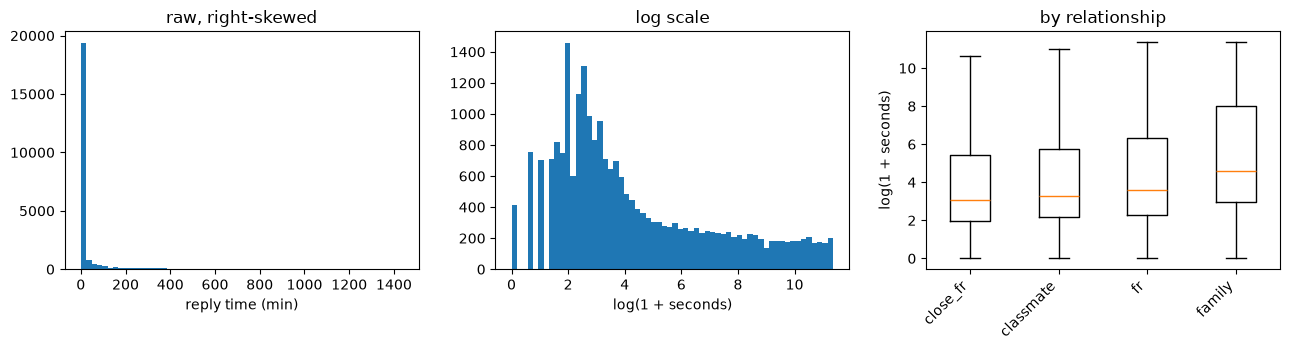

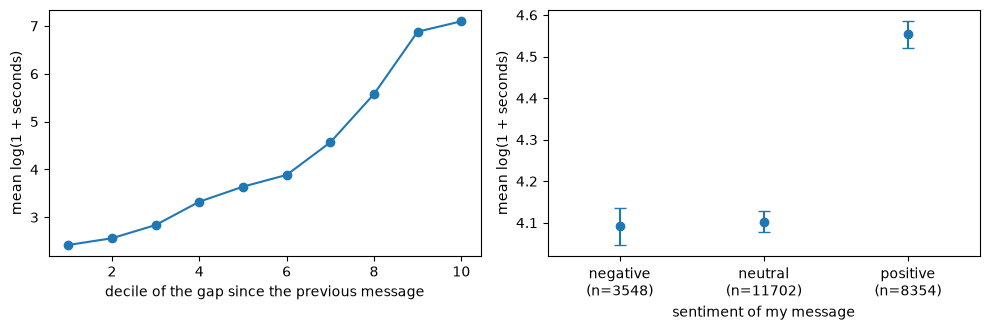

eta^2 = 0.11
correlation with y:


,corr
log_prev_gap,0.551
prev_from_them,-0.281
has_media,0.167
has_exclaim,0.154
log_n_msgs,0.120
age,0.110
has_question,0.107
sentiment,0.092
log_len,0.045
hours_since_midnight,0.031


median reply time in minutes by language group:


,median_min
lang_group,
en,0.5
ru_uk,0.4


In [3]:
d = D_burst
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(d["delay"] / 60, bins=60)
axes[0].set_xlabel("reply time (min)")
axes[0].set_title("raw, right-skewed")
axes[1].hist(d["y"], bins=60)
axes[1].set_xlabel("log(1 + seconds)")
axes[1].set_title("log scale")
order = list(d.groupby("relationship")["y"].median().sort_values().index)
axes[2].boxplot([d.loc[d["relationship"] == r, "y"] for r in order], showfliers=False)
axes[2].set_xticks(range(1, len(order) + 1))
axes[2].set_xticklabels(order, rotation=45, ha="right")
axes[2].set_title("by relationship")
axes[2].set_ylabel("log(1 + seconds)")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_target.pdf")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
gap_decile = pd.qcut(d["log_prev_gap"], 10, labels=False, duplicates="drop")
by_gap = d.groupby(gap_decile)["y"].mean()
axes[0].plot(by_gap.index + 1, by_gap.values, marker="o")
axes[0].set_xlabel("decile of the gap since the previous message")
axes[0].set_ylabel("mean log(1 + seconds)")
sent_group = pd.cut(d["sentiment"], [-1.01, -0.05, 0.05, 1.01], labels=["negative", "neutral", "positive"])
by_sent = d.groupby(sent_group, observed=True)["y"].agg(["mean", "std", "size"])
axes[1].errorbar(range(len(by_sent)), by_sent["mean"], yerr=by_sent["std"] / np.sqrt(by_sent["size"]),
                 fmt="o", capsize=4)
axes[1].set_xlim(-0.5, len(by_sent) - 0.5)
axes[1].set_xticks(range(len(by_sent)))
axes[1].set_xticklabels([f"{name}\n(n={n})" for name, n in zip(by_sent.index, by_sent["size"])])
axes[1].set_xlabel("sentiment of my message")
axes[1].set_ylabel("mean log(1 + seconds)")
plt.tight_layout()
plt.savefig(FIG_DIR / "patterns.pdf")
plt.show()

ss_total = ((d["y"] - d["y"].mean()) ** 2).sum()
ss_within = ((d["y"] - d.groupby("pid")["y"].transform("mean")) ** 2).sum()
eta_sq = 1 - ss_within / ss_total
print(f"eta^2 = {eta_sq:.2f}")

numeric_cols = FEATURE_SETS["all"][0]
corr = d[numeric_cols].corrwith(d["y"]).round(3)
print("correlation with y:")
display(corr.sort_values(key=np.abs, ascending=False).to_frame("corr"))
print("median reply time in minutes by language group:")
display((d.groupby("lang_group")["delay"].median() / 60).round(1).to_frame("median_min"))

## Part 7: The models

Features are standardised (mean 0, standard deviation 1) inside every training fold. The target is $\log(1+\text{seconds})$. The derivations are in the report, this is the short version.

* Mean baseline: always predicts the mean of the training targets. A useful model has to beat it.
* Linear regression (by hand): with the design matrix $A=[\mathbf 1\ X]$ it minimises the mean squared error $\frac1n\|y-A\beta\|^2$. Setting the gradient to zero gives the normal equations $A^\top A\beta=A^\top y$, which the code solves directly, so there is no iterative training. I check the result against scikit-learn.
* Random forest (library): $B$ regression trees $T_b$, each grown on a bootstrap sample and allowed to look at a random half of the features at every split. A split is chosen to minimise the squared error left in the two children. The forest predicts $\hat f(x)=\frac1B\sum_b T_b(x)$, which lowers the variance because the trees make partly different mistakes.
* Gradient boosting (library): start from $F_0=\bar y$ and for $m=1,\dots,M$ fit a small tree $h_m$ to the residuals $r_i=y_i-F_{m-1}(x_i)$ (the negative gradient of $\frac12(y-F)^2$), then set $F_m=F_{m-1}+\nu h_m$ with a small learning rate $\nu$.

The settings of the two ensembles are reasonable defaults and are not tuned.

In [4]:
class Standardizer:
    """Rescale every column to mean 0 and standard deviation 1."""

    def fit(self, X):
        """Remember the mean and standard deviation of each column."""
        self.mean = X.mean(axis=0)
        std = X.std(axis=0)
        self.std = np.where(std < 1e-12, 1.0, std)   # a constant column would divide by zero
        return self

    def transform(self, X):
        """Apply the remembered rescaling."""
        return (X - self.mean) / self.std


class LinearRegressionScratch:
    """Linear regression fitted with the normal equations."""

    def fit(self, X, y):
        """Find the coefficients beta, the first entry is the intercept."""
        A = np.c_[np.ones(len(X)), X]
        # the tiny 1e-8 keeps the system solvable if a dummy column is constant in a training fold
        self.beta = np.linalg.solve(A.T @ A + 1e-8 * np.eye(A.shape[1]), A.T @ y)
        return self

    def predict(self, X):
        """Predicted y for new rows."""
        return np.c_[np.ones(len(X)), X] @ self.beta


class MeanBaseline:
    """Predicts the mean of the training targets for every row."""

    def fit(self, X, y):
        """Store the mean of y."""
        self.mean = np.mean(y)
        return self

    def predict(self, X):
        """Same prediction for every row."""
        return np.full(len(X), self.mean)


def make_models():
    """Fresh untrained copies of all models, a new copy is needed for every fold."""
    return {
        "Mean baseline": MeanBaseline(),
        "OLS (scratch)": LinearRegressionScratch(),
        "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=30, max_features=0.5,
                                               n_jobs=-1, random_state=SEED),
        "Gradient boosting": GradientBoostingRegressor(n_estimators=250, learning_rate=0.03, max_depth=3,
                                                       subsample=0.7, min_samples_leaf=30, random_state=SEED),
    }


X, y, groups, columns = make_xy(D_burst, "all")
X_scaled = Standardizer().fit(X).transform(X)
mine = LinearRegressionScratch().fit(X_scaled, y)
library = LinearRegression().fit(X_scaled, y)
diff_library = np.abs(mine.beta - np.r_[library.intercept_, library.coef_]).max()
print("my linear regression vs scikit-learn, largest coefficient difference:", diff_library)
assert diff_library < 1e-8

my linear regression vs scikit-learn, largest coefficient difference: 1.8030021919912542e-12


## Part 8: Cross-validation and metrics

Messages from one contact are very similar to each other (someone who is slow stays slow). If a random split puts some of a contact's messages into training and others into testing, the model can learn the person and the score looks better than it should. So every contact goes entirely into training or entirely into testing. My version of group k-fold hands out the contacts one by one, biggest first, to the fold that currently has the fewest messages, so the folds are about the same size. I repeat it with different random seeds.

The metrics are computed on the held-out contacts. With $\hat y_i$ the prediction and $\bar y_{\text{tr}}$ the mean of the training targets,

$$\mathrm{RMSE}=\sqrt{\tfrac1n\sum(y_i-\hat y_i)^2},\qquad \mathrm{MAE}=\tfrac1n\sum|y_i-\hat y_i|,\qquad R^2_{\text{oos}}=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y_{\text{tr}})^2}.$$

$R^2_{\text{oos}}$ compares the model with predicting the training mean, so it can be negative.

In [5]:
def group_kfold(groups, k=5, seed=0):
    """Yield (train rows, test rows) for k folds, every group lands in exactly one test fold.

    Groups are handed out biggest first, each to the fold with the fewest rows so far.
    """
    rng = np.random.default_rng(seed)
    names, sizes = np.unique(groups, return_counts=True)
    order = rng.permutation(len(names))
    order = order[np.argsort(-sizes[order], kind="stable")]   # biggest first, random among equal sizes
    fold_of = {}
    fold_sizes = np.zeros(k)
    for j in order:
        f = int(np.argmin(fold_sizes))
        fold_of[names[j]] = f
        fold_sizes[f] += sizes[j]
    fold = np.array([fold_of[g] for g in groups])
    for f in range(k):
        yield np.where(fold != f)[0], np.where(fold == f)[0]


def rmse(y, pred):
    """Root mean squared error."""
    return np.sqrt(np.mean((y - pred) ** 2))


def mae(y, pred):
    """Mean absolute error."""
    return np.mean(np.abs(y - pred))


def r2_oos(y, pred, train_mean):
    """Out-of-sample R squared, measured against predicting the training mean."""
    return 1 - np.sum((y - pred) ** 2) / np.sum((y - train_mean) ** 2)


def cross_validate(model_name, X, y, groups, k=5, seeds=(0,)):
    """Group k-fold cross-validation, returns one row of metrics per fold and seed."""
    rows = []
    for seed in seeds:
        for fold, (train, test) in enumerate(group_kfold(groups, k, seed)):
            scaler = Standardizer().fit(X[train])   # statistics from the training fold only
            model = make_models()[model_name]
            model.fit(scaler.transform(X[train]), y[train])
            pred = model.predict(scaler.transform(X[test]))
            rows.append({"seed": seed, "fold": fold, "rmse": rmse(y[test], pred), "mae": mae(y[test], pred),
                         "r2": r2_oos(y[test], pred, y[train].mean())})
    return pd.DataFrame(rows)


def summarize(results, by):
    """Mean and standard deviation of every metric over folds and seeds."""
    grouped = results.groupby(by)[["rmse", "mae", "r2"]]
    return grouped.mean().round(3).join(grouped.std().round(3), rsuffix="_sd")

## Part 9: Experiments

Experiment 1 runs all models on the burst version and on the naive version of the data, with two random seeds. The two versions have different rows and a different spread of the target, so their RMSE values are not directly comparable. Each model should be compared with the mean baseline inside the same version.

Experiment 2 is the feature ablation on the burst data. It shows whether sentiment adds anything, whether the contact labels help, and how far the message and context features get on their own.

Experiment 3 is about language. It fits separate models for en and ru_uk chats and one pooled model, and it also trains on one language group and tests on the other.

In [6]:
MODEL_NAMES = list(make_models())

results = []
for data_name, data in [("burst", D_burst), ("naive", D_naive)]:
    X, y, groups, columns = make_xy(data, "all")
    for model_name in MODEL_NAMES:
        res = cross_validate(model_name, X, y, groups, seeds=(0, 1))
        results.append(res.assign(dataset=data_name, model=model_name))
results_main = pd.concat(results)
table_main = summarize(results_main, ["dataset", "model"])
display(table_main)

rmse    mae     r2  rmse_sd  mae_sd  r2_sd
dataset model                                                         
burst   Gradient boosting  2.233  1.676  0.373    0.163   0.134  0.024
        Mean baseline      2.818  2.314  0.000    0.156   0.097  0.000
        OLS (scratch)      2.323  1.753  0.322    0.187   0.146  0.037
        Random forest      2.226  1.678  0.377    0.158   0.134  0.021
naive   Gradient boosting  2.409  1.915  0.195    0.112   0.078  0.026
        Mean baseline      2.684  2.218  0.000    0.087   0.071  0.000
        OLS (scratch)      2.469  1.970  0.154    0.096   0.071  0.022
        Random forest      2.421  1.923  0.186    0.106   0.079  0.027

In [7]:
results = []
for feature_set in FEATURE_SETS:
    X, y, groups, columns = make_xy(D_burst, feature_set)
    for model_name in ["Mean baseline", "OLS (scratch)", "Gradient boosting"]:
        res = cross_validate(model_name, X, y, groups)
        results.append(res.assign(features=feature_set, model=model_name))
table_ablation = summarize(pd.concat(results), ["features", "model"])
display(table_ablation)

rmse    mae     r2  rmse_sd  mae_sd  r2_sd
features     model                                                         
all          Gradient boosting  2.234  1.677  0.373    0.174   0.143  0.025
             Mean baseline      2.818  2.314  0.000    0.166   0.104  0.000
             OLS (scratch)      2.323  1.753  0.322    0.200   0.157  0.040
contact_only Gradient boosting  2.854  2.301 -0.025    0.238   0.263  0.087
             Mean baseline      2.818  2.314  0.000    0.166   0.104  0.000
             OLS (scratch)      2.801  2.278  0.013    0.221   0.173  0.056
message_only Gradient boosting  2.229  1.674  0.375    0.163   0.129  0.023
             Mean baseline      2.818  2.314  0.000    0.166   0.104  0.000
             OLS (scratch)      2.320  1.752  0.323    0.180   0.137  0.028
no_sentiment Gradient boosting  2.237  1.681  0.371    0.174   0.144  0.025
             Mean baseline      2.818  2.314  0.000    0.166   0.104  0.000
             OLS (scratch)      2.326  1.755  0.320    0.201   0.159  0.040

In [8]:
def transfer(data, train_lang, test_lang, model_name):
    """Train on the chats of one language group and test on the chats of the other."""
    X, y, groups, columns = make_xy(data, "all")
    is_train = (data["lang_group"] == train_lang).to_numpy()
    is_test = (data["lang_group"] == test_lang).to_numpy()
    scaler = Standardizer().fit(X[is_train])
    model = make_models()[model_name]
    model.fit(scaler.transform(X[is_train]), y[is_train])
    pred = model.predict(scaler.transform(X[is_test]))
    return {"model": model_name, "train": train_lang, "test": test_lang, "rmse": round(rmse(y[is_test], pred), 3),
            "r2": round(r2_oos(y[is_test], pred, y[is_train].mean()), 3)}


subsets = [("en", D_burst[D_burst["lang_group"] == "en"]),
           ("ru_uk", D_burst[D_burst["lang_group"] == "ru_uk"]),
           ("both", D_burst)]
results = []
for subset_name, data in subsets:
    X, y, groups, columns = make_xy(data, "all")
    n_contacts = len(np.unique(groups))
    for model_name in ["Mean baseline", "OLS (scratch)", "Gradient boosting"]:
        res = cross_validate(model_name, X, y, groups, k=min(5, n_contacts))
        results.append(res.assign(subset=subset_name, model=model_name))
table_language = summarize(pd.concat(results), ["subset", "model"])
display(table_language)

rows = []
for model_name in ["OLS (scratch)", "Gradient boosting"]:
    rows.append(transfer(D_burst, "en", "ru_uk", model_name))
    rows.append(transfer(D_burst, "ru_uk", "en", model_name))
table_transfer = pd.DataFrame(rows)
display(table_transfer)

rmse    mae     r2  rmse_sd  mae_sd  r2_sd
subset model                                                         
both   Gradient boosting  2.234  1.677  0.373    0.174   0.143  0.025
       Mean baseline      2.818  2.314  0.000    0.166   0.104  0.000
       OLS (scratch)      2.323  1.753  0.322    0.200   0.157  0.040
en     Gradient boosting  2.280  1.736  0.360    0.151   0.094  0.025
       Mean baseline      2.850  2.369  0.000    0.179   0.139  0.000
       OLS (scratch)      2.385  1.830  0.300    0.170   0.106  0.021
ru_uk  Gradient boosting  2.196  1.653  0.395    0.330   0.320  0.059
       Mean baseline      2.823  2.254  0.000    0.370   0.201  0.000
       OLS (scratch)      2.248  1.696  0.366    0.351   0.332  0.074

,model,train,test,rmse,r2
0,OLS (scratch),en,ru_uk,2.611,0.101
1,OLS (scratch),ru_uk,en,2.508,0.231
2,Gradient boosting,en,ru_uk,2.207,0.357
3,Gradient boosting,ru_uk,en,2.337,0.332


### Figures for the comparisons and the final performance

The next cells draw three figures. The first compares the conditions of experiments 1 to 3 in one place, using the tables above (bars are mean $R^2_{\text{oos}}$, whiskers are the standard deviation over folds).

The second shows how gradient boosting learns. With $F_m$ the model after $m$ trees, I fit it on the training contacts of every fold and record the RMSE of $F_m$ on the training rows and on the held-out contacts for $m=1,\dots,M$. The held-out curve shows when more trees stop helping.

The third shows the final performance of gradient boosting on the burst data. Every point is a message whose prediction came from a model that never saw its contact (out-of-fold prediction).

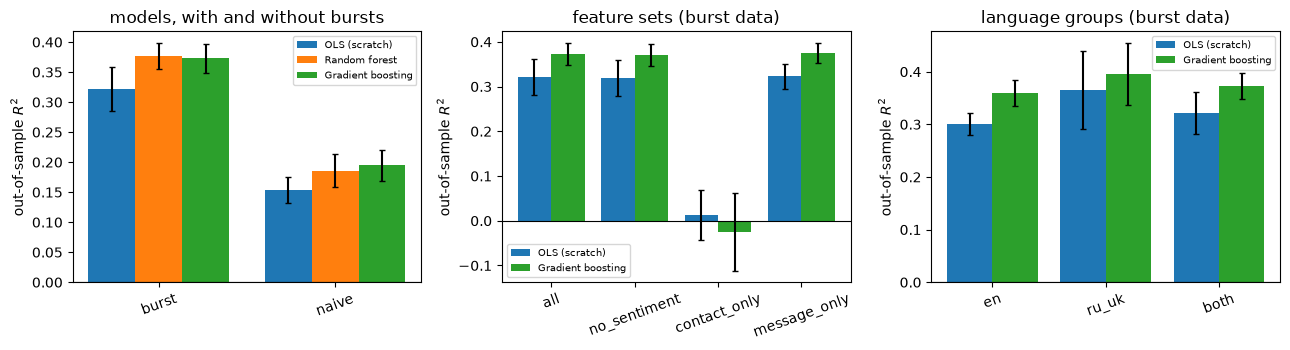

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (table, level, title, order) in zip(axes, [
        (table_main, "dataset", "models, with and without bursts", ["burst", "naive"]),
        (table_ablation, "features", "feature sets (burst data)", list(FEATURE_SETS)),
        (table_language, "subset", "language groups (burst data)", ["en", "ru_uk", "both"])]):
    models = ["OLS (scratch)", "Random forest", "Gradient boosting"] if level == "dataset" else ["OLS (scratch)", "Gradient boosting"]
    width = 0.8 / len(models)
    colors = {"OLS (scratch)": "tab:blue", "Random forest": "tab:orange", "Gradient boosting": "tab:green"}
    for k, model_name in enumerate(models):
        r2 = [table.loc[(g, model_name), "r2"] for g in order]
        sd = [table.loc[(g, model_name), "r2_sd"] for g in order]
        ax.bar(np.arange(len(order)) + k * width, r2, width, yerr=sd, capsize=2, label=model_name, color=colors[model_name])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(np.arange(len(order)) + width * (len(models) - 1) / 2)
    ax.set_xticklabels(order, rotation=20)
    ax.set_ylabel("out-of-sample $R^2$")
    ax.set_title(title)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIG_DIR / "comparison.pdf")
plt.show()

held-out RMSE: 2.789 after 1 tree, lowest 2.233 after 192 of 250 trees, 2.234 after the last tree (baseline 2.818)
training RMSE after the last tree: 2.172


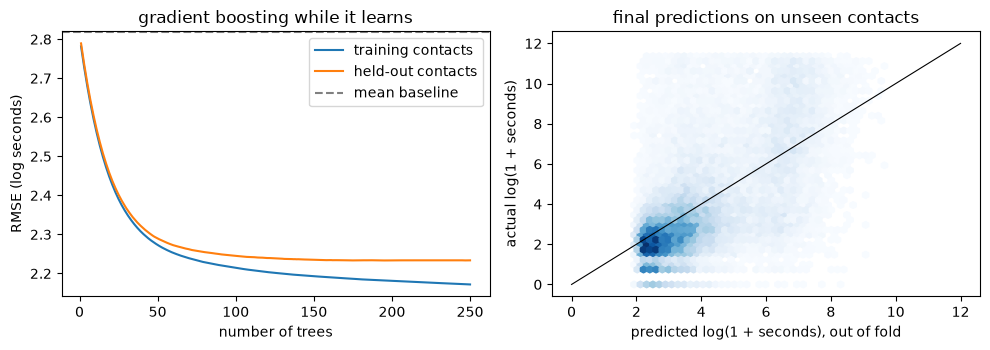

In [10]:
X, y, groups, columns = make_xy(D_burst, "all")
n_trees = make_models()["Gradient boosting"].n_estimators
k = 5
train_curve = np.zeros((k, n_trees))
test_curve = np.zeros((k, n_trees))
baseline_rmse = np.zeros(k)
out_of_fold = np.zeros(len(y))

for f, (train, test) in enumerate(group_kfold(groups, k, seed=0)):
    scaler = Standardizer().fit(X[train])
    model = make_models()["Gradient boosting"].fit(scaler.transform(X[train]), y[train])
    stages = zip(model.staged_predict(scaler.transform(X[train])), model.staged_predict(scaler.transform(X[test])))
    for m, (pred_train, pred_test) in enumerate(stages):
        train_curve[f, m] = rmse(y[train], pred_train)
        test_curve[f, m] = rmse(y[test], pred_test)
    out_of_fold[test] = pred_test            # prediction after the last tree
    baseline_rmse[f] = rmse(y[test], np.full(len(test), y[train].mean()))

best = int(test_curve.mean(axis=0).argmin()) + 1
print(f"held-out RMSE: {test_curve.mean(axis=0)[0]:.3f} after 1 tree, lowest {test_curve.mean(axis=0).min():.3f} "
      f"after {best} of {n_trees} trees, {test_curve.mean(axis=0)[-1]:.3f} after the last tree (baseline {baseline_rmse.mean():.3f})")
print(f"training RMSE after the last tree: {train_curve.mean(axis=0)[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
steps = np.arange(1, n_trees + 1)
axes[0].plot(steps, train_curve.mean(axis=0), label="training contacts")
axes[0].plot(steps, test_curve.mean(axis=0), label="held-out contacts")
axes[0].axhline(baseline_rmse.mean(), color="gray", linestyle="dashed", label="mean baseline")
axes[0].set_xlabel("number of trees")
axes[0].set_ylabel("RMSE (log seconds)")
axes[0].set_title("gradient boosting while it learns")
axes[0].legend()

axes[1].hexbin(out_of_fold, y, gridsize=40, mincnt=1, cmap="Blues")
axes[1].plot([0, 12], [0, 12], color="black", linewidth=0.8)
axes[1].set_xlabel("predicted log(1 + seconds), out of fold")
axes[1].set_ylabel("actual log(1 + seconds)")
axes[1].set_title("final predictions on unseen contacts")
plt.tight_layout()
plt.savefig(FIG_DIR / "learning_and_performance.pdf")
plt.show()

## Part 10: What the models learned

Permutation importance on held-out contacts: in every held-out fold I shuffle one feature column and see how much the RMSE goes up. A big increase means the model relies on that feature.

$$\mathrm{PI}_j=\mathrm{RMSE}(X^{(\pi_j)})-\mathrm{RMSE}(X).$$

For the linear regression coefficients I use a bootstrap over contacts: resample the contacts with replacement, refit, and take the 2.5% and 97.5% percentiles of every coefficient. Ordinary standard errors assume independent rows, but rows from one contact are correlated. Coefficients are per standard deviation of the feature, and because the target is $\log(1+\Delta)$, $e^{\beta}$ is roughly the factor by which the reply time is multiplied.

Finally, who the contact is explains part of the variance, so the question "does the sentiment of a message change how fast the same person replies?" is asked after subtracting each contact's own mean from both $y$ and the sentiment $s$:

$$\tilde y_i=y_i-\bar y_{c(i)},\qquad \tilde s_i=s_i-\bar s_{c(i)},\qquad \tilde y\sim\tilde s .$$

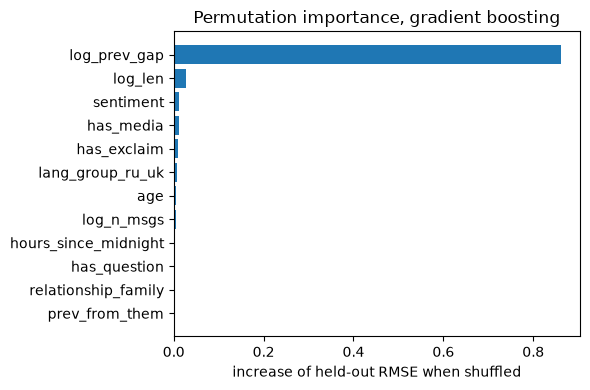

In [11]:
def permutation_importance(model_name, X, y, groups, columns, k=5, repeats=5, seed=0):
    """Increase of the held-out RMSE when one feature column is shuffled, averaged over folds."""
    rng = np.random.default_rng(seed)
    increase = np.zeros((k, len(columns)))
    for f, (train, test) in enumerate(group_kfold(groups, k, seed)):
        scaler = Standardizer().fit(X[train])
        model = make_models()[model_name]
        model.fit(scaler.transform(X[train]), y[train])
        X_test = scaler.transform(X[test])
        base = rmse(y[test], model.predict(X_test))
        for j in range(len(columns)):
            for _ in range(repeats):
                X_shuffled = X_test.copy()
                X_shuffled[:, j] = rng.permutation(X_shuffled[:, j])
                increase[f, j] += (rmse(y[test], model.predict(X_shuffled)) - base) / repeats
    return pd.Series(increase.mean(axis=0), index=columns).sort_values(ascending=False)


def cluster_bootstrap(X, y, groups, n_boot=300, seed=0):
    """Refit the linear regression on contacts resampled with replacement, returns all coefficients."""
    rng = np.random.default_rng(seed)
    names = np.unique(groups)
    rows_of = {name: np.where(groups == name)[0] for name in names}
    coefs = []
    for _ in range(n_boot):
        chosen = rng.choice(names, size=len(names), replace=True)   # whole contacts, not single rows
        idx = np.concatenate([rows_of[name] for name in chosen])
        scaler = Standardizer().fit(X[idx])
        model = LinearRegressionScratch().fit(scaler.transform(X[idx]), y[idx])
        coefs.append(model.beta[1:])
    return np.array(coefs)


X, y, groups, columns = make_xy(D_burst, "all")
importance = permutation_importance("Gradient boosting", X, y, groups, columns)
top_features = importance.head(12)[::-1]
plt.figure(figsize=(6, 4))
plt.barh(top_features.index, top_features.values)
plt.xlabel("increase of held-out RMSE when shuffled")
plt.title("Permutation importance, gradient boosting")
plt.tight_layout()
plt.savefig(FIG_DIR / "perm_importance.pdf")
plt.show()

In [12]:
beta = LinearRegressionScratch().fit(Standardizer().fit(X).transform(X), y).beta[1:]
boot = cluster_bootstrap(X, y, groups)
low, high = np.percentile(boot, [2.5, 97.5], axis=0)
coef = pd.DataFrame({"coef_per_sd": beta, "ci_low": low, "ci_high": high}, index=columns)
coef["excludes_0"] = np.where((low > 0) | (high < 0), "yes", "no")
coef = coef.reindex(coef["coef_per_sd"].abs().sort_values(ascending=False).index)
coef.index.name = "feature"
display(coef.round(3))

d = D_burst
s_centered = (d["sentiment"] - d.groupby("pid")["sentiment"].transform("mean")).to_numpy()[:, None]
y_centered = (d["y"] - d.groupby("pid")["y"].transform("mean")).to_numpy()
slope = LinearRegressionScratch().fit(Standardizer().fit(s_centered).transform(s_centered), y_centered).beta[1]
boot = cluster_bootstrap(s_centered, y_centered, d["pid"].to_numpy())[:, 0]
low, high = np.percentile(boot, [2.5, 97.5])
print(f"effect of sentiment inside a contact: {slope:+.3f} per standard deviation "
      f"(95% interval [{low:+.3f}, {high:+.3f}])")
print(f"the reply time is multiplied by about {np.exp(slope):.2f} for a message that is 1 s.d. more positive")

,coef_per_sd,ci_low,ci_high,excludes_0
feature,,,,
log_prev_gap,1.389,1.300,1.464,yes
lang_group_ru_uk,-0.267,-0.458,-0.077,yes
relationship_family,0.261,-0.037,0.650,no
has_media,0.233,0.170,0.295,yes
has_exclaim,0.185,0.127,0.237,yes
sentiment,0.141,0.105,0.185,yes
relationship_fr,0.121,-0.045,0.274,no
log_n_msgs,0.112,0.066,0.174,yes
sex_M,-0.083,-0.246,0.048,no


effect of sentiment inside a contact: +0.198 per standard deviation (95% interval [+0.159, +0.251])
the reply time is multiplied by about 1.22 for a message that is 1 s.d. more positive
